# How fine can a hidden ripple be?
### A two-sided logarithmic law for the resolution gap of the arrow of time — interactive demo

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neginyan/resolution-gap-two-sided/blob/main/demo/hidden_ripple_demo.ipynb)

A state can carry a ripple finer than the width $\sigma$ of the observer's blur.  The *resolution gap* $g$ measures how much of the
arrow of time such a hidden ripple can still show.  The paper proves that its smallest value over the periodic-window class obeys

$$\Big(1-\bar\varepsilon\Big)\Big(1-1.7\,\frac{\ln\ell}{\ell}\Big)\;\le\; g_{\min}\sqrt{\ell} \;\le\; \big(1+|\varepsilon(S'_C(\sigma))|\big)\Big(1+6.0\,\frac{\ln\ell}{\ell}\Big),
\qquad \ell=\ln(1/\sigma),\quad 10^{-100000}\le\sigma\le10^{-24}.$$

Both sides are computer-assisted proofs (the lower side: 421 cells; the upper side: 1464 decimal-interval cells on an explicit comb sequence).
This notebook shows, on a CPU in a few minutes,

1. the band between the two proved bounds closing onto 1, with the certificates' own values and the exact evaluator's points;
2. the "256× sharper lens": a comb window equals a strip window at $\sigma/256$;
3. one cell of the upper certificate recomputed here, with $h<0$.

Code and stored results: https://github.com/neginyan/resolution-gap-two-sided

In [1]:
# Setup: use this repository if the notebook runs inside it; otherwise (Colab) clone it.
import os, sys, subprocess, time, json, glob
if os.path.exists('verification/run_all.py'):
    pass
elif os.path.exists('../verification/run_all.py'):
    os.chdir('..')
else:
    if not os.path.exists('resolution-gap-two-sided'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/neginyan/resolution-gap-two-sided'], check=True)
    os.chdir('resolution-gap-two-sided')
ROOT = os.getcwd()
for d in ('src', 'certificates', 'experiments', 'verification'):
    sys.path.insert(0, os.path.join(ROOT, d))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
J = lambda f: json.load(open(os.path.join(ROOT, 'results', f)))
print('repository root:', ROOT)
print('numpy', np.__version__)

repository root: /home/claude/repo/resolution-gap-two-sided
numpy 2.5.3


## 1. The band closes onto 1

Horizontal axis: $\ell=\ln(1/\sigma)$ on a log scale (top axis: $\sigma$).  Vertical axis: $g\sqrt{\ell}$.

* **Shaded band** — the two proved bounds $1-1.7\ln\ell/\ell$ and $1+6.0\ln\ell/\ell$ (drawn with $\varepsilon=0$), on the proved range $10^{-100000}\le\sigma\le10^{-24}$.
* **Blue steps** — the lower certificate's own value $L_\text{cell}$ on each of its 421 cells (stored; $g_{\min}\sqrt\ell\ge(1-\bar\varepsilon)L_\text{cell}$).
* **Orange curve** — $U_P\sqrt\ell$ on the comb sequence $S'_C(\sigma)$, recomputed here from the closed form in 60-digit decimal arithmetic ($g(S'_C)\le(1+|\varepsilon|)U_P$).
* **Points** — the exact gap $g\sqrt\ell$ of the strip sequence $S'$ and the comb sequence $S'_C$ from paper E's evaluator, at the $\sigma$ where it can be run ($10^{-6}$ to $10^{-24}$; stored results).  The comb lies below the strip.

In [2]:
from decimal import Decimal as D
from ba_ivl import I, Dl
from bf_cert_upper import h_of

# lower certificate (stored)
C = {}
for f in sorted(glob.glob(os.path.join(ROOT, 'results', 'bh_cert_cells_part*.json'))):
    C.update(json.load(open(f)))
cells = sorted(C.values(), key=lambda v: v['la'])
print('lower certificate: %d cells, all conditions hold: %s' % (len(cells), all(c['ok'] for c in cells)))

# U_P sqrt(l) on the comb sequence, recomputed (60-digit decimal intervals); k runs over the certificate's range
t0 = time.time(); ks = np.geomspace(3.43, 240.0, 90); Ucurve = []
for k in ks:
    _, Uv, t = h_of(Dl(I(D(repr(float(k)))), I(0)))
    Ucurve.append((float(t.v.hi), float(Uv.v.hi) * float(t.v.hi) ** 0.5))
Ucurve = np.array(Ucurve)
print('U_P sqrt(l) at %d points recomputed in %.1f s: %.4f at l = %.1f  ->  %.6f at l = %.0f' % (
    len(ks), time.time() - t0, Ucurve[0, 1], Ucurve[0, 0], Ucurve[-1, 1], Ucurve[-1, 0]))

# exact evaluator (stored): strip sequence S' and comb sequence S'_C
S = J('az_upper.json')['true']; CB = J('bf_upper_full.json')['true']
print('\n sigma    l      strip g*sqrt(l)   comb g*sqrt(l)   comb eps')
for s in ('1e-06', '1e-12', '1e-18', '1e-24'):
    l = np.log(1 / float(s))
    print('%6s  %6.2f      %.4f           %.4f        %+.1e' % (s, l, S[s]['g_sqrt_ln'], CB[s]['g_sqrt_ln'], CB[s]['eps']))

lower certificate: 421 cells, all conditions hold: True
U_P sqrt(l) at 90 points recomputed in 0.9 s: 1.4311 at l = 55.1  ->  1.000180 at l = 230455

 sigma    l      strip g*sqrt(l)   comb g*sqrt(l)   comb eps
 1e-06   13.82      3.2953           2.3504        -6.1e-07
 1e-12   27.63      2.1504           1.7898        +4.0e-13
 1e-18   41.45      1.7354           1.5459        -1.5e-15
 1e-24   55.26      1.5357           1.4157        +3.6e-16


width of the proved band:  0.559 at sigma = 1e-24,  0.0259 at 1e-1000,  0.00041 at 1e-100000
lower certificate L_cell:  0.88999 (1e-24)  ->  0.99995 (last cell)
upper certificate U_P sqrt(l): 1.43106 (l = 55)  ->  1.00019 (l = 230455)
scaled constants on the certified range: lower -1.614 ... -0.765 (>= -1.7),  upper 3.363 ... 5.922 (<= 6.0)


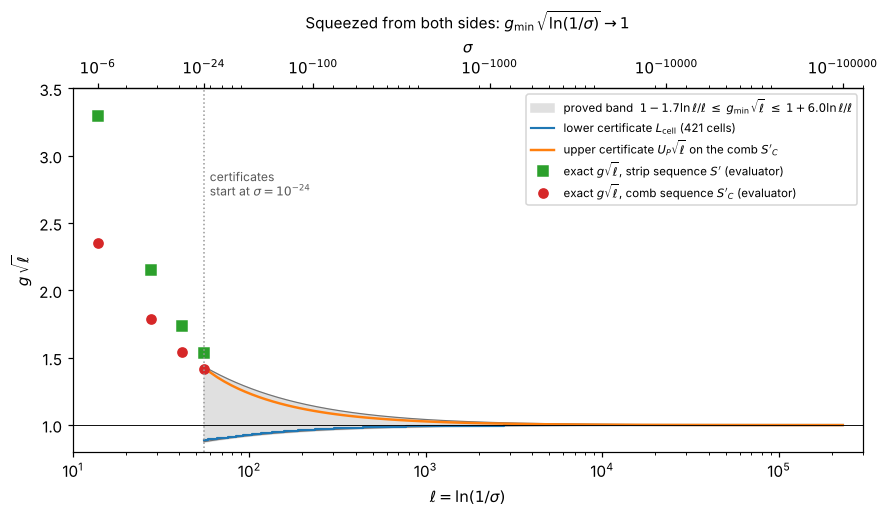

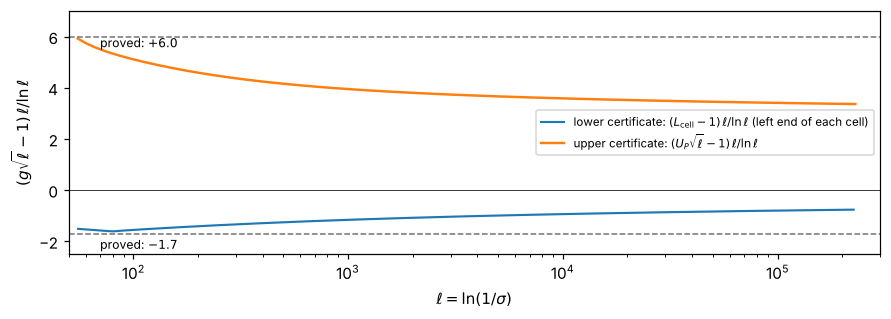

In [3]:
L_LO, L_HI = 24 * np.log(10), 1e5 * np.log(10)
l = np.geomspace(L_LO, L_HI, 400)
lo = 1 - 1.7 * np.log(l) / l; up = 1 + 6.0 * np.log(l) / l

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.fill_between(l, lo, up, color='0.88', label='proved band  $1-1.7\\ln\\ell/\\ell \\;\\leq\\; g_{\\min}\\sqrt{\\ell} \\;\\leq\\; 1+6.0\\ln\\ell/\\ell$')
ax.plot(l, lo, color='0.45', lw=0.8); ax.plot(l, up, color='0.45', lw=0.8)
xs = [c['la'] for c in cells] + [cells[-1]['lb']]; ys = [c['L_cell'] for c in cells] + [cells[-1]['L_cell']]
ax.step(xs, ys, where='post', color='tab:blue', lw=1.4, label='lower certificate $L_{\\rm cell}$ (421 cells)')
ax.plot(Ucurve[:, 0], Ucurve[:, 1], color='tab:orange', lw=1.6, label="upper certificate $U_P\\sqrt{\\ell}$ on the comb $S'_C$")
le = [np.log(1 / float(s)) for s in ('1e-06', '1e-12', '1e-18', '1e-24')]
ax.plot(le, [S[s]['g_sqrt_ln'] for s in ('1e-06', '1e-12', '1e-18', '1e-24')], 's', color='tab:green', ms=6, label="exact $g\\sqrt{\\ell}$, strip sequence $S'$ (evaluator)")
ax.plot(le, [CB[s]['g_sqrt_ln'] for s in ('1e-06', '1e-12', '1e-18', '1e-24')], 'o', color='tab:red', ms=6, label="exact $g\\sqrt{\\ell}$, comb sequence $S'_C$ (evaluator)")
ax.axvline(L_LO, color='0.6', ls=':', lw=1); ax.text(L_LO * 1.08, 2.9, 'certificates\nstart at $\\sigma=10^{-24}$', fontsize=8, color='0.35', va='top')
ax.axhline(1, color='k', lw=0.6)
ax.set_xscale('log'); ax.set_xlim(10, 3e5); ax.set_ylim(0.8, 3.5)
ax.set_xlabel('$\\ell = \\ln(1/\\sigma)$'); ax.set_ylabel('$g\\,\\sqrt{\\ell}$')
top = ax.secondary_xaxis('top', functions=(lambda x: x, lambda x: x))
ticks = [6, 24, 100, 1000, 10000, 100000]
top.set_xticks([e * np.log(10) for e in ticks]); top.set_xticklabels(['$10^{-%d}$' % e for e in ticks]); top.set_xlabel('$\\sigma$')
ax.legend(fontsize=7.6, loc='upper right'); ax.set_title('Squeezed from both sides: $g_{\\min}\\sqrt{\\ln(1/\\sigma)}\\to 1$', fontsize=10)
plt.tight_layout(); plt.show()

print('width of the proved band:  %.3f at sigma = 1e-24,  %.4f at 1e-1000,  %.5f at 1e-100000' % tuple(
    (6.0 + 1.7) * np.log(x) / x for x in (L_LO, 1000 * np.log(10), L_HI)))
dn = lambda x: np.floor(x * 1e5) / 1e5; upr = lambda x: np.ceil(x * 1e5) / 1e5      # lower bounds rounded down, upper bounds up
print('lower certificate L_cell:  %.5f (1e-24)  ->  %.5f (last cell)' % (dn(cells[0]['L_cell']), dn(cells[-1]['L_cell'])))
print('upper certificate U_P sqrt(l): %.5f (l = %.0f)  ->  %.5f (l = %.0f)' % (upr(Ucurve[0, 1]), Ucurve[0, 0], upr(Ucurve[-1, 1]), Ucurve[-1, 0]))

# the same data, distance from 1 in units of ln(l)/l: the proved constants are -1.7 and 6.0
fig, ax = plt.subplots(figsize=(8.2, 3.0))
la = np.array([c['la'] for c in cells]); Lc = np.array([c['L_cell'] for c in cells])
ax.plot(la, (Lc - 1) * la / np.log(la), color='tab:blue', lw=1.4, label='lower certificate: $(L_{\\rm cell}-1)\\,\\ell/\\ln\\ell$ (left end of each cell)')
ax.plot(Ucurve[:, 0], (Ucurve[:, 1] - 1) * Ucurve[:, 0] / np.log(Ucurve[:, 0]), color='tab:orange', lw=1.6, label="upper certificate: $(U_P\\sqrt{\\ell}-1)\\,\\ell/\\ln\\ell$")
ax.axhline(-1.7, color='0.45', ls='--', lw=1); ax.axhline(6.0, color='0.45', ls='--', lw=1); ax.axhline(0, color='k', lw=0.5)
ax.text(70, -2.3, 'proved: $-1.7$', fontsize=8); ax.text(70, 5.55, 'proved: $+6.0$', fontsize=8)
ax.set_xscale('log'); ax.set_xlim(50, 3e5); ax.set_ylim(-2.5, 7); ax.set_xlabel('$\\ell = \\ln(1/\\sigma)$'); ax.set_ylabel('$(g\\sqrt{\\ell}-1)\\,\\ell/\\ln\\ell$')
ax.legend(fontsize=7.6, loc='center right'); plt.tight_layout(); plt.show()
print('scaled constants on the certified range: lower %.3f ... %.3f (>= -1.7),  upper %.3f ... %.3f (<= 6.0)' % (
    ((Lc - 1) * la / np.log(la)).min(), ((Lc - 1) * la / np.log(la)).max(),
    ((Ucurve[:, 1] - 1) * Ucurve[:, 0] / np.log(Ucurve[:, 0])).min(), ((Ucurve[:, 1] - 1) * Ucurve[:, 0] / np.log(Ucurve[:, 0])).max()))

**Reading the picture.**  Every state of the class sits above the blue steps (times $1-\bar\varepsilon$), and the comb sequence sits below the orange curve
(times $1+|\varepsilon(S'_C)|$; the evaluator gives $|\varepsilon(S'_C)|$ between $6\times10^{-7}$ and $4\times10^{-16}$ at the four points — a numerical value, not a proof).
So $g_{\min}\sqrt{\ln(1/\sigma)}$ is trapped in a band whose width shrinks like $\ln\ell/\ell$.
Beyond $10^{-100000}$ the lower side is still proved ($\liminf\ge1-\bar\varepsilon$); the upper side there is a derivation.
The evaluator points lie to the left of the certified range: the evaluator resolves the state on a grid and cannot be run at much smaller $\sigma$ — that is exactly why the certificates work with closed-form bounds.

## 2. The "256× sharper lens"

A periodic window multiplies the state by $1+\sum_n a_n\cos(n k v)$ inside an envelope.
* **strip**: one harmonic, $1+c\cos(kv)$ with $c\le1$ (positivity);
* **comb**: Gaussian teeth, $a_n=2e^{-n^2\tau^2/2}$ — the fundamental amplitude goes up to $a_1\to2$.

At leading order the gap depends on the amplitude only through $\sigma/a^8$ (Proposition 14 of the paper, an exact identity of the leading-order formula):
$$g_{\rm LO}(\sigma;\,a)=g_{\rm LO}(\sigma/a^8;\,1)\,\frac{1+r'}{1+a^4r'},\qquad a=2\;\Rightarrow\;\sigma/a^8=\sigma/256 .$$
So the comb at $\sigma$ behaves like the strip seen through a lens 256 times sharper.

Fourier series and Poisson form agree: largest difference 3.2e-14 (peak height 40.1)
strip: a_1 = 1 (largest allowed for one harmonic, minimum 0.000);  comb: a_1 = 2 exp(-tau^2/2) = 1.9960975622, minimum 0.0e+00


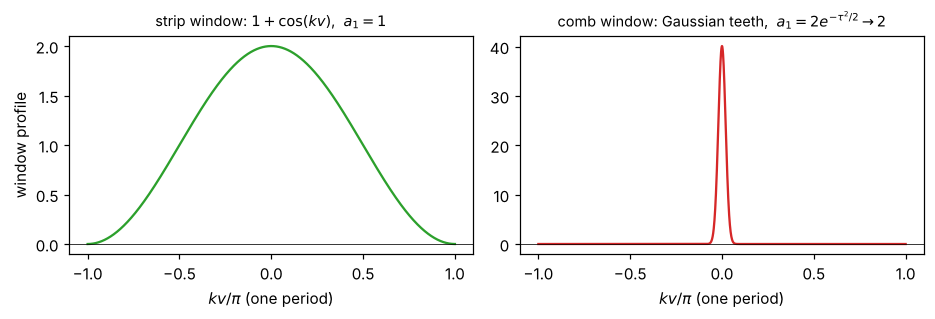

In [4]:
u = np.linspace(-np.pi, np.pi, 2001)
k0 = 4.0; tau = 1 / k0 ** 2                       # a comb of the sequence S'_C at k0 = 4 (sigma ~ 1e-28); teeth width tau
n = np.arange(1, 400)
comb_fourier = 1 + np.sum((2 * np.exp(-(n[:, None] * tau) ** 2 / 2)) * np.cos(n[:, None] * u), axis=0)
# the same function by Poisson summation: a row of Gaussian teeth of width tau, one per period (manifestly positive)
comb = np.sqrt(2 * np.pi) / tau * sum(np.exp(-(u - 2 * np.pi * m) ** 2 / (2 * tau ** 2)) for m in (-1, 0, 1))
print('Fourier series and Poisson form agree: largest difference %.1e (peak height %.1f)' % (np.abs(comb - comb_fourier).max(), comb.max()))
strip = 1 + 1.0 * np.cos(u)

fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.0))
axs[0].plot(u / np.pi, strip, color='tab:green'); axs[0].set_title('strip window: $1+\\cos(kv)$,  $a_1 = 1$', fontsize=9.5)
axs[1].plot(u / np.pi, comb, color='tab:red'); axs[1].set_title('comb window: Gaussian teeth,  $a_1 = 2e^{-\\tau^2/2}\\to 2$', fontsize=9.5)
for a in axs: a.set_xlabel('$kv/\\pi$ (one period)'); a.axhline(0, color='k', lw=0.5)
axs[0].set_ylabel('window profile'); plt.tight_layout(); plt.show()
print('strip: a_1 = 1 (largest allowed for one harmonic, minimum %.3f);  comb: a_1 = 2 exp(-tau^2/2) = %.10f, minimum %.1e' % (strip.min(), 2 * np.exp(-tau ** 2 / 2), comb.min()))

In [5]:
from bd_comb_lo import gmin          # leading-order minimum over the periodic-window family with fundamental amplitude <= cmax
t0 = time.time()
print('   sigma     strip g_LO(sigma)   comb g_LO(sigma)   strip g_LO(sigma/256)   comb / strip(sigma/256)')
for e in (12, 24, 96, 1024):
    ls = -e * np.log(10)
    gs = gmin(ls, 1.0)[0]; gc = gmin(ls, 2.0)[0]; gsh = gmin(ls - 8 * np.log(2), 1.0)[0]
    print('  1e-%-5d    %.10f       %.10f        %.10f           %.12f' % (e, gs, gc, gsh, gc / gsh))
print('(recomputed here in %.0f s)' % (time.time() - t0))
LOt = J('be_lo.json')
print('\nstored check of the identity at 2000 random parameter sets: largest relative deviation %.1e' % LOt['identity_max_dev'])

   sigma     strip g_LO(sigma)   comb g_LO(sigma)   strip g_LO(sigma/256)   comb / strip(sigma/256)
  1e-12       0.3352403159       0.2788745253        0.2788745541           0.999999896587
  1e-24       0.1793789686       0.1667226277        0.1667226277           1.000000000000
  1e-96       0.0727749888       0.0717527551        0.0717527551           1.000000000000
  1e-1024     0.0207866998       0.0207618901        0.0207618901           1.000000000000
(recomputed here in 12 s)

stored check of the identity at 2000 random parameter sets: largest relative deviation 2.3e-13


The comb at $\sigma$ and the strip at $\sigma/256$ agree to 7–15 digits: the comb is the strip with a 256× sharper lens.  Because the gap falls as
$\sigma$ shrinks, the comb is lower than the strip at the same $\sigma$ (at leading order by the factor $1-4\ln2/\ln(1/\sigma)+\dots$); the exact evaluator
confirms the order (comb below strip at all four points of Section 1).  This is why the upper certificate is run on the comb sequence $S'_C$.

In [6]:
# exact evaluator (stored): comb and strip at the same sigma
print('  sigma    strip g (exact)   comb g (exact)   comb/strip')
for s in ('1e-06', '1e-12', '1e-18', '1e-24'):
    L = np.log(1 / float(s))
    print('  %s     %.6f         %.6f        %.4f' % (s, S[s]['g_true'], CB[s]['g_true'], CB[s]['g_true'] / S[s]['g_true']))

  sigma    strip g (exact)   comb g (exact)   comb/strip
  1e-06     0.886570         0.632338        0.7132
  1e-12     0.409098         0.340490        0.8323
  1e-18     0.269556         0.240129        0.8908
  1e-24     0.206580         0.190440        0.9219


## 3. Check one cell of the upper certificate here

The upper certificate proves, for every $k$ in $[3.43,\,240]$ (that is $10^{-100000}\lesssim\sigma\le10^{-24}$ on the comb sequence),
$$h(k)=U_P(k)\sqrt{t(k)}-1-6.0\,\frac{\ln t(k)}{t(k)}<0,\qquad t(k)=\ln(1/\sigma).$$
It covers $[3.43,240]$ with 1464 cells and bounds $h$ on each by $h(m)+\max|h'|\,(b-a)/2$, with outward-rounded 60-digit decimal interval
arithmetic.  The cell below is recomputed from scratch; change `a` to any cell start.

In [7]:
from bf_cert_upper import cell_bound, t_of as t_of_
a = D('3.43'); k = a; cells_k = []
while k < D('240.0'):                                # the certificate's cell boundaries
    b = min(k + D('0.02') * (1 + k / 10), D('240.0')); cells_k.append((k, b)); k = b
print('the certificate uses %d cells' % len(cells_k))
for (a, b) in (cells_k[0], cells_k[700], cells_k[-1]):
    t0 = time.time(); ub, hm = cell_bound(a, b)
    print('cell k in [%.6f, %.6f]  (ln(1/sigma) from %.1f to %.1f):  h(midpoint) <= %.6e,  h <= %.6e on the whole cell  ->  h < 0: %s   (%.2f s)' % (
        float(a), float(b), float(t_of_(a).hi), float(t_of_(b).lo), float(hm), float(ub), ub < 0, time.time() - t0))

the certificate uses 1464 cells
cell k in [3.430000, 3.456860]  (ln(1/sigma) from 55.1 to 55.9):  h(midpoint) <= -6.850128e-03,  h <= -5.357430e-03 on the whole cell  ->  h < 0: True   (0.02 s)
cell k in [44.385244, 44.494015]  (ln(1/sigma) from 7916.4 to 7955.1):  h(midpoint) <= -2.706251e-03,  h <= -2.691539e-03 on the whole cell  ->  h < 0: True   (0.02 s)
cell k in [239.777096, 240.000000]  (ln(1/sigma) from 230027.0 to 230454.7):  h(midpoint) <= -1.414206e-04,  h <= -1.400063e-04 on the whole cell  ->  h < 0: True   (0.02 s)


In [8]:
CU = J('bf_cert_upper.json')
print('stored certificate:', CU['claim'])
print('  cells %s, all certified: %s, largest upper bound of h: %s' % (CU['cells'], CU['all_cells_certified'], CU['worst_upper_bound_of_h']))
print('\nTo re-run every certificate:  python verification/run_all.py --recompute   (about 20 minutes on one core)')

stored certificate: h = U_P sqrt(ln) - 1 - 6.0 lnln/ln < 0 for 1e-100000 <= sigma <= 1e-24 on the comb sequence S'_C
  cells 1464, all certified: True, largest upper bound of h: -0.00013503519513771814

To re-run every certificate:  python verification/run_all.py --recompute   (about 20 minutes on one core)


---
*What is proved and what is not.*  Lower bound for $10^{-100000}\le\sigma\le10^{-24}$ and its limit $\liminf\ge1-\bar\varepsilon$: proof (computer-assisted).
Upper bound on the same range: proof (computer-assisted), with the factor $1+|\varepsilon(S'_C)|$; the smallness of $\varepsilon(S'_C)$ is numerical.
The upper limit beyond $10^{-100000}$: derivation.  The evaluator points and the leading-order table are numerical illustrations.